# Figure 5 — Proteomes of four larval tissues

**Run order:** fig2 → fig3 → **fig5** → fig6. Fig 6 reads the tissue-enriched protein list written here.

| Output | What | File (in `outputs/`) |
|---|---|---|
| **Fig 5A** (heatmap) | Per-tissue median abundance of all proteins, grouped by tissue of maximal abundance | `fig5/fig5A_proteome_heatmap` |
| **Fig 5B** | % of proteome differing ≥ 2-fold between tissue pairs | `fig5/fig5B_pairwise_diff_matrix` |
| **Fig 5C** | FlyBase gene-group violins across tissues | `fig5/fig5C_gene_group_violins` |
| **Fig 5D** | Tissue-prevalent (2–10×) and tissue-enriched (> 10×) proteins | `fig5/fig5D_enriched_stacked_bars` |
| **Fig 5E** | GO enrichment of tissue-enriched proteins | `fig5/fig5E_go_dotplot` |
| **Fig S3** | Replicate concordance per tissue | `fig5/figS3_replicate_pair_density` |
| **Supplementary Table S5** | All proteins with medians, pairwise FC / adj. p, enriched_in / prevalent_in | `supplementary_tables/Table_S5_larval_tissues_all_proteins.csv` |
| **Supplementary Table S6** | Tissue-enriched proteins (subset of S5) | `supplementary_tables/Table_S6_larval_tissue_enriched_proteins.csv` |
| *for Fig 6* | Tissue-enriched proteins (`exclusive_to`), used for Fig 6B–E and Fig S5 | `intermediate/larva_tissue_enriched_proteins.csv` |

Fig 5A (schematic) is not produced here. In the tables, `gut` is written as `intestine`.

**Inputs:** `raw data/protein_quant_2241_cns20_larva_tissues.tsv`, `helper files/genetable.xlsx`, `helper files/gene_group_data_fb_2025_05.tsv.gz`.
Fig 5E queries the g:Profiler web service (needs internet).

**Statistics.** Pairwise Welch t-tests on the normalised values (no imputation; zeros replaced by half the smallest
non-zero value), BH-FDR over all pairs. A protein is *tissue-enriched* in T if it is significantly higher in T than in
each other tissue and its smallest log2FC ≥ 3.33. The intestine has three replicates (gutA excluded).

In [1]:
from itertools import combinations
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.cm import ScalarMappable
from matplotlib.colors import LinearSegmentedColormap, LogNorm, Normalize
import matplotlib.colors as mcolors
from matplotlib.lines import Line2D
from scipy.stats import pearsonr, ttest_ind
from statsmodels.stats.multitest import multipletests
from adjustText import adjust_text

import common as cm
from common import TISSUE_COLORS_DARK, TISSUE_COLORS_LIGHT, TISSUE_LABELS

OUT = cm.fig_dir('fig5')
QUANT_FILE = cm.DATA_DIR / 'protein_quant_2241_cns20_larva_tissues.tsv'
cm.require(QUANT_FILE, cm.GENETABLE, cm.GENE_GROUP_FILE)

LOG2FC_THRESHOLD = 3.33     # tissue-enriched cutoff (log2, ~10-fold)
PVALUE_THRESHOLD = 0.05     # BH-adjusted p-value cutoff

## Load and normalise

In [2]:
all_channels = ['126_sn', '127n_sn', '127c_sn', '128n_sn',
                '128c_sn', '129n_sn', '129c_sn', '130n_sn',
                '130c_sn', '131n_sn', '131c_sn', '132n_sn',
                '133n_sn', '133c_sn', '134n_sn']          # 132c_sn (gutA) excluded
experiment_channels = ['brainA', 'brainB', 'brainC', 'brainD',
                       'mtA', 'mtB', 'mtC', 'mtD',
                       'discsA', 'discsB', 'discsC', 'discsD',
                       'gutB', 'gutC', 'gutD']
result = cm.normalize_tmt(QUANT_FILE, all_channels, experiment_channels, min_sumSN=300)

# tissue -> its replicate columns (strip '_norm' and the replicate letter)
cond_to_cols = {}
for ch in experiment_channels:
    cond_to_cols.setdefault(ch[:-1], []).append(f'{ch}_norm')
tissues = list(cond_to_cols)
print(cond_to_cols)

protein_quant_2241_cns20_larva_tissues.tsv: 8498 rows -> 8170 pass S/N + decoy filter -> 8139 with gene annotation
{'brain': ['brainA_norm', 'brainB_norm', 'brainC_norm', 'brainD_norm'], 'mt': ['mtA_norm', 'mtB_norm', 'mtC_norm', 'mtD_norm'], 'discs': ['discsA_norm', 'discsB_norm', 'discsC_norm', 'discsD_norm'], 'gut': ['gutB_norm', 'gutC_norm', 'gutD_norm']}


## Fig S3 — replicate concordance per tissue
Per tissue: proteins measured in every replicate (no CV filter). Pearson r for every replicate pair;
the pair whose r is closest to the median r is shown, labelled with the median r.

brain: kept 8139 | median r = 0.9434 | range [0.8854, 0.9781] | shown ('brainA_norm', 'brainB_norm')
mt: kept 8139 | median r = 0.9735 | range [0.9577, 0.9842] | shown ('mtB_norm', 'mtD_norm')
discs: kept 8139 | median r = 0.7494 | range [0.5449, 0.9470] | shown ('discsC_norm', 'discsD_norm')
gut: kept 8139 | median r = 0.8411 | range [0.8098, 0.9131] | shown ('gutB_norm', 'gutD_norm')


Saved fig5/figS3_replicate_pair_density.pdf / .png


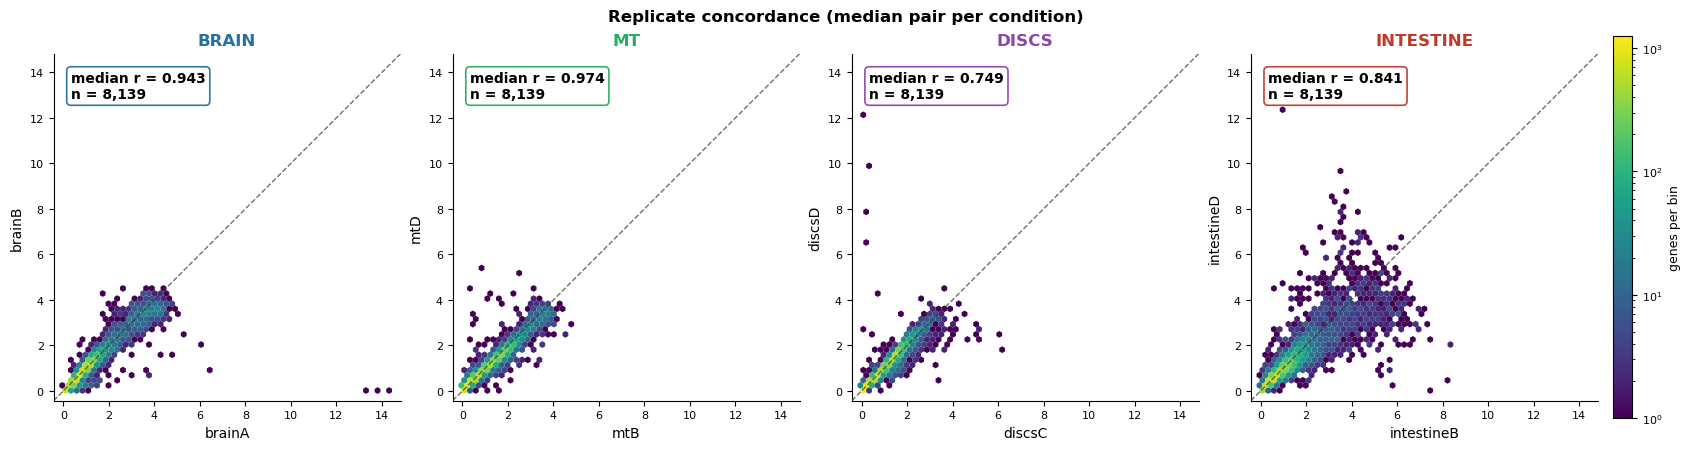

In [3]:
CV_THRESHOLD = None     # None = no CV filter (was 0.7)
keep_masks, rep_pairs = {}, {}
for t, cols in cond_to_cols.items():
    sub = result[cols]
    keep = sub.notna().all(axis=1)
    if CV_THRESHOLD is not None:
        keep &= sub.std(axis=1, ddof=1) / sub.mean(axis=1) <= CV_THRESHOLD
    keep_masks[t] = keep
    pair_rs = []
    for a, b in combinations(cols, 2):
        mask = result[a].notna() & result[b].notna() & keep
        pair_rs.append((pearsonr(result.loc[mask, a], result.loc[mask, b])[0], (a, b)))
    r_values = np.array([r for r, _ in pair_rs])
    median_r = float(np.median(r_values))
    rep_pairs[t] = (min(pair_rs, key=lambda p: abs(p[0] - median_r))[1], median_r)
    print(f'{t}: kept {int(keep.sum())} | median r = {median_r:.4f} | '
          f'range [{r_values.min():.4f}, {r_values.max():.4f}] | shown {rep_pairs[t][0]}')

panels, gmin, gmax = {}, np.inf, -np.inf
for t, ((a, b), median_r) in rep_pairs.items():
    mask = result[a].notna() & result[b].notna() & keep_masks[t]
    xl, yl = result.loc[mask, a].values, result.loc[mask, b].values
    panels[t] = (a, b, xl, yl, median_r)
    gmin, gmax = min(gmin, xl.min(), yl.min()), max(gmax, xl.max(), yl.max())
pad = 0.03 * (gmax - gmin)
lims = [gmin - pad, gmax + pad]

fig, axes = plt.subplots(1, len(panels), figsize=(4.2 * len(panels), 4.4), constrained_layout=True)
hexes, counts_max = [], 0
for ax, t in zip(axes, panels):
    a, b, xl, yl, median_r = panels[t]
    accent = TISSUE_COLORS_DARK[t]
    hb = ax.hexbin(xl, yl, gridsize=60, cmap='viridis', mincnt=1, linewidths=0.0,
                   extent=(lims[0], lims[1], lims[0], lims[1]), rasterized=True)
    hexes.append(hb)
    counts_max = max(counts_max, hb.get_array().max())
    ax.plot(lims, lims, ls='--', color='#333333', lw=1.0, alpha=0.7, zorder=3)
    ax.set_xlim(lims); ax.set_ylim(lims); ax.set_aspect('equal')
    ax.text(0.05, 0.95, f'median r = {median_r:.3f}\nn = {xl.size:,}', transform=ax.transAxes,
            fontsize=10, fontweight='bold', va='top', ha='left',
            bbox=dict(boxstyle='round,pad=0.3', facecolor='white', edgecolor=accent, linewidth=1.2, alpha=0.95))
    ax.set_xlabel(a.replace('_norm', '').replace('gut', 'intestine'), fontsize=10)
    ax.set_ylabel(b.replace('_norm', '').replace('gut', 'intestine'), fontsize=10)
    ax.set_title(TISSUE_LABELS[t], fontsize=12, fontweight='bold', color=accent, pad=6)
    ax.spines[['top', 'right']].set_visible(False)
    ax.tick_params(labelsize=8)
norm = LogNorm(vmin=1, vmax=counts_max)
for hb in hexes:
    hb.set_norm(norm)
cbar = fig.colorbar(hexes[-1], ax=axes, fraction=0.025, pad=0.01)
cbar.set_label('genes per bin', fontsize=9)
cbar.ax.tick_params(labelsize=8)
fig.suptitle('Replicate concordance (median pair per condition)', fontsize=12, fontweight='bold')
cm.save_fig(fig, OUT, 'figS3_replicate_pair_density')
plt.show()

## Pairwise statistics and tissue-enrichment calls
Zeros are replaced by half the smallest non-zero value (affects the statistics and every panel below; Fig S3 above
uses the values before replacement).

In [4]:
test_cols = [c for cols in cond_to_cols.values() for c in cols]
vals = result[test_cols].values
epsilon = vals[(vals != 0) & ~np.isnan(vals)].min() / 2
print(f'Zeros replaced: {int((result[test_cols] == 0).sum().sum())}  (epsilon = {epsilon:.4g})')
result[test_cols] = result[test_cols].replace(0, epsilon)


def test_tissue_enrichment(data, cond_to_cols, log2fc_threshold, fdr_threshold):
    """Every ordered tissue pair: FC = median_target / median_other, Welch t-test, BH over all pairs.
    exclusive_to = the tissue (if any) with FC >= 2**log2fc_threshold and padj < fdr vs every other tissue."""
    tissues = list(cond_to_cols)
    pairs = [(a, b) for a in tissues for b in tissues if a != b]
    n = len(data)
    medians = {t: data[cols].median(axis=1, skipna=True) for t, cols in cond_to_cols.items()}

    fc_data, pval_data = {}, {}
    for a, b in pairs:
        fc_data[f'fc_{a}_vs_{b}'] = (medians[a] / medians[b]).values
        A, B = data[cond_to_cols[a]].values, data[cond_to_cols[b]].values
        pvals = np.full(n, np.nan)
        for i in range(n):
            x, y = A[i][~np.isnan(A[i])], B[i][~np.isnan(B[i])]
            if len(x) < 2 or len(y) < 2:
                continue
            if np.std(x, ddof=1) == 0 and np.std(y, ddof=1) == 0:
                pvals[i] = 1.0 if np.mean(x) == np.mean(y) else 0.0
            else:
                pvals[i] = ttest_ind(x, y, equal_var=False)[1]
        pval_data[f'padj_{a}_vs_{b}'] = pvals

    # BH across ALL p-values (NaN -> non-significant)
    names = list(pval_data)
    flat = np.column_stack([pval_data[k] for k in names]).flatten()
    nan = np.isnan(flat); flat[nan] = 1.0
    adj = multipletests(flat, method='fdr_bh')[1]; adj[nan] = np.nan
    adj = adj.reshape(n, len(names))

    res = data.copy().reset_index(drop=True)
    for t in tissues:
        res[f'{t}_median'] = medians[t].values
    for k, v in fc_data.items():
        res[k] = v
    for j, k in enumerate(names):
        res[k] = adj[:, j]

    res['exclusive_to'] = ''
    for t in tissues:
        others = [o for o in tissues if o != t]
        hit = np.logical_and.reduce([(res[f'fc_{t}_vs_{o}'] >= 2 ** log2fc_threshold)
                                     & (res[f'padj_{t}_vs_{o}'] < fdr_threshold) for o in others])
        res.loc[hit, 'exclusive_to'] = t
    for t in tissues:
        print(f"  {t}: {(res['exclusive_to'] == t).sum()} tissue-enriched")
    return res


results = test_tissue_enrichment(result, cond_to_cols, LOG2FC_THRESHOLD, PVALUE_THRESHOLD)

Zeros replaced: 817  (epsilon = 8.093e-11)


C:\Users\am9341\AppData\Local\anaconda3\envs\chromium_env\Lib\site-packages\scipy\stats\_axis_nan_policy.py:579: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  res = hypotest_fun_out(*samples, **kwds)


C:\Users\am9341\AppData\Local\anaconda3\envs\chromium_env\Lib\site-packages\scipy\stats\_axis_nan_policy.py:579: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  res = hypotest_fun_out(*samples, **kwds)


C:\Users\am9341\AppData\Local\anaconda3\envs\chromium_env\Lib\site-packages\scipy\stats\_axis_nan_policy.py:579: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  res = hypotest_fun_out(*samples, **kwds)


C:\Users\am9341\AppData\Local\anaconda3\envs\chromium_env\Lib\site-packages\scipy\stats\_axis_nan_policy.py:579: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  res = hypotest_fun_out(*samples, **kwds)


...

C:\Users\am9341\AppData\Local\anaconda3\envs\chromium_env\Lib\site-packages\scipy\stats\_axis_nan_policy.py:579: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  res = hypotest_fun_out(*samples, **kwds)


C:\Users\am9341\AppData\Local\anaconda3\envs\chromium_env\Lib\site-packages\scipy\stats\_axis_nan_policy.py:579: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  res = hypotest_fun_out(*samples, **kwds)


C:\Users\am9341\AppData\Local\anaconda3\envs\chromium_env\Lib\site-packages\scipy\stats\_axis_nan_policy.py:579: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  res = hypotest_fun_out(*samples, **kwds)


C:\Users\am9341\AppData\Local\anaconda3\envs\chromium_env\Lib\site-packages\scipy\stats\_axis_nan_policy.py:579: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  res = hypotest_fun_out(*samples, **kwds)


  brain: 363 tissue-enriched
  mt: 173 tissue-enriched
  discs: 32 tissue-enriched
  gut: 230 tissue-enriched


## Supplementary Tables S5 and S6
Same tiers as Fig 5D, with padj < 0.05 vs every other tissue and the smallest fold change (vs the closest tissue):
`enriched_in` = min FC ≥ 2^3.33 (~10-fold); `prevalent_in` = 2 ≤ min FC < 2^3.33.
Table S6 = rows of S5 with `enriched_in` set (the 798 proteins of Fig 5D).

In [5]:
PREVALENT_MIN_FC = 2
ENRICHED_MIN_FC  = 2 ** LOG2FC_THRESHOLD      # same cutoff as Fig 5D and exclusive_to
results['enriched_in'] = ''
results['prevalent_in'] = ''
for t in tissues:
    others = [o for o in tissues if o != t]
    min_fc = results[[f'fc_{t}_vs_{o}' for o in others]].min(axis=1, skipna=False)
    sig    = (results[[f'padj_{t}_vs_{o}' for o in others]] < PVALUE_THRESHOLD).all(axis=1)
    results.loc[sig & (min_fc >= PREVALENT_MIN_FC) & (min_fc < ENRICHED_MIN_FC), 'prevalent_in'] = t
    results.loc[sig & (min_fc >= ENRICHED_MIN_FC), 'enriched_in'] = t
assert (results['enriched_in'] == results['exclusive_to']).all()

pairs = [(a, b) for a in tissues for b in tissues if a != b]
export_cols = (['ProteinId', 'Number of peptides', 'sumSN'] + test_cols
               + ['gene_ID', 'gene_symbol', 'gene_fullname', 'polypeptide_symbol']
               + [f'{t}_median' for t in tissues]
               + [f'fc_{a}_vs_{b}' for a, b in pairs] + [f'padj_{a}_vs_{b}' for a, b in pairs]
               + ['enriched_in', 'prevalent_in'])

def gut_to_intestine(df):
    df = df.rename(columns=lambda c: c.replace('gut', 'intestine'))
    return df.replace({'enriched_in': {'gut': 'intestine'}, 'prevalent_in': {'gut': 'intestine'}})

table_s5 = results[export_cols]
table_s6 = table_s5[table_s5['enriched_in'] != ''].sort_values(['enriched_in', 'ProteinId'])
cm.save_table(gut_to_intestine(table_s5), 'Table_S5_larval_tissues_all_proteins')
cm.save_table(gut_to_intestine(table_s6), 'Table_S6_larval_tissue_enriched_proteins')
print(table_s6['enriched_in'].value_counts().to_string())

# For Fig 6: tissue-enriched proteins (min log2FC >= 3.33 vs every other tissue)
enriched = results[results['exclusive_to'] != ''].copy()
enriched.insert(0, 'tissue', enriched['exclusive_to'])
enriched.to_csv(cm.INTERMEDIATE_DIR / 'larva_tissue_enriched_proteins.csv', index=False)
print(f'Tissue-enriched proteins for Fig 5D/E and Fig 6: {len(enriched)}')

Saved Table_S5_larval_tissues_all_proteins.csv  (8,139 rows x 52 columns)
Saved Table_S6_larval_tissue_enriched_proteins.csv  (798 rows x 52 columns)
enriched_in
brain    363
gut      230
mt       173
discs     32
Tissue-enriched proteins for Fig 5D/E and Fig 6: 798


## Fig 5A — proteome heatmap
Per-tissue medians (no z-scoring), proteins grouped by the tissue with the highest median and sorted within block.

C:\Users\am9341\AppData\Local\Temp\ipykernel_46268\1511632230.py:45: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved fig5/fig5A_proteome_heatmap.pdf / .png


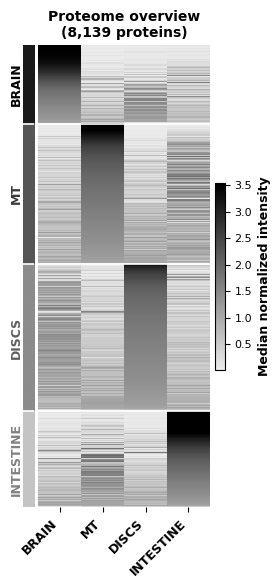

In [6]:
CMAP_GRAY    = LinearSegmentedColormap.from_list('gray_light_to_black', ['#EBEBEB', '#000000'])
TISSUE_GRAYS = {'brain': '#1A1A1A', 'mt': '#555555', 'discs': '#8C8C8C', 'gut': '#C4C4C4'}
LABEL_GRAYS  = {'brain': '#000000', 'mt': '#3A3A3A', 'discs': '#5E5E5E', 'gut': '#808080'}

M = results[[f'{t}_median' for t in tissues]].copy()
M.columns = tissues
Mv = M[M.notna().all(axis=1) & (M > 0).all(axis=1)].reset_index(drop=True)
dominant = np.array(tissues)[Mv.values.argmax(axis=1)]

order_idx, block_bounds, cursor = [], {}, 0
for t in tissues:
    in_t = np.where(dominant == t)[0]
    in_t = in_t[np.argsort(-Mv[t].values[in_t])]
    block_bounds[t] = (cursor, cursor + len(in_t))
    order_idx.extend(in_t.tolist())
    cursor += len(in_t)
order_idx = np.array(order_idx)
D = Mv.values[order_idx]
norm = Normalize(*np.percentile(D, (2, 98)))
n_rows = len(order_idx)

fig, (axc, ax) = plt.subplots(1, 2, figsize=(2.6, 6), gridspec_kw={'width_ratios': [0.06, 1], 'wspace': 0.04})
strip = np.array([mcolors.to_rgb(TISSUE_GRAYS[t]) for t in dominant[order_idx]])[:, None, :]
axc.imshow(strip, aspect='auto', origin='upper')
axc.set_xticks([]); axc.set_yticks([])
for s in axc.spines.values():
    s.set_visible(False)
ax.imshow(D, aspect='auto', cmap=CMAP_GRAY, norm=norm, origin='upper', interpolation='nearest')
for t in tissues:
    s, e = block_bounds[t]
    if e < n_rows:
        ax.axhline(e - 0.5, color='white', lw=1.2)
        axc.axhline(e - 0.5, color='white', lw=1.2)
    axc.text(-1.1, (s + e) / 2 - 0.5, TISSUE_LABELS[t], rotation=90, ha='center', va='center',
             fontsize=9, fontweight='bold', color=LABEL_GRAYS[t])
ax.set_xticks(range(len(tissues)))
ax.set_xticklabels([TISSUE_LABELS[t] for t in tissues], fontsize=9, fontweight='bold', rotation=45, ha='right')
ax.set_yticks([])
ax.set_title(f'Proteome overview\n({n_rows:,} proteins)', fontsize=10, fontweight='bold', pad=6)
for s in ax.spines.values():
    s.set_visible(False)
cbar = fig.colorbar(ScalarMappable(cmap=CMAP_GRAY, norm=norm), ax=ax, fraction=0.05, pad=0.03)
cbar.set_label('Median normalized intensity', fontsize=9, fontweight='bold')
cbar.ax.tick_params(labelsize=8)
plt.tight_layout()
cm.save_fig(fig, OUT, 'fig5A_proteome_heatmap')
plt.show()

## Fig 5B — % of proteome differing between tissue pairs
Different = padj < 0.05 and |log2FC| ≥ 1 (either direction); denominator = all quantified proteins.

  row   col  n_diff  pct
   mt brain    5306 65.2
discs brain    2208 27.1
discs    mt    5158 63.4
  gut brain    4597 56.5
  gut    mt    2312 28.4
  gut discs    4815 59.2


Saved fig5/fig5B_pairwise_diff_matrix.pdf / .png


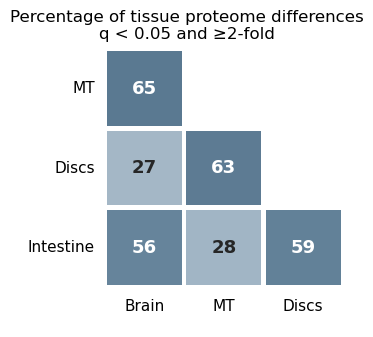

In [7]:
MIN_LOG2FC = 1.0
order   = ['brain', 'mt', 'discs', 'gut']
display = {'brain': 'Brain', 'mt': 'MT', 'discs': 'Discs', 'gut': 'Intestine'}
n = len(order)

rows = []
for r in range(1, n):
    for c in range(r):
        a, b = order[c], order[r]
        log2fc = np.log2(results[f'fc_{a}_vs_{b}'].clip(lower=1e-10))
        diff = (((results[f'padj_{a}_vs_{b}'] < PVALUE_THRESHOLD) & (log2fc >= MIN_LOG2FC))
                | ((results[f'padj_{b}_vs_{a}'] < PVALUE_THRESHOLD) & (log2fc <= -MIN_LOG2FC)))
        rows.append({'row': b, 'col': a, 'n_diff': int(diff.sum()), 'pct': 100 * diff.sum() / len(results)})
table = pd.DataFrame(rows)
print(table.assign(pct=table['pct'].round(1)).to_string(index=False))

cmap = LinearSegmentedColormap.from_list('slate', ['#E3EAF0', '#6F8CA3', '#2B4E68'])
norm = mcolors.Normalize(vmin=0, vmax=100)
cell, gap = 1.0, 0.06
fig, ax = plt.subplots(figsize=(0.9 * (n - 1) + 1.4, 0.9 * (n - 1) + 1.3))
for _, rw in table.iterrows():
    x, y = order.index(rw['col']) * cell, -((order.index(rw['row']) - 1) * cell)
    color = cmap(norm(rw['pct']))
    ax.add_patch(plt.Rectangle((x + gap / 2, y + gap / 2), cell - gap, cell - gap, facecolor=color, edgecolor='none'))
    lum = 0.299 * color[0] + 0.587 * color[1] + 0.114 * color[2]
    ax.text(x + cell / 2, y + cell / 2, f"{rw['pct']:.0f}", ha='center', va='center', fontsize=13,
            fontweight='bold', color='white' if lum < 0.55 else '0.15')
for r, t in enumerate(order[1:]):
    ax.text(-0.12, -(r * cell) + cell / 2, display[t], ha='right', va='center', fontsize=11)
for c, t in enumerate(order[:-1]):
    ax.text(c * cell + cell / 2, -((n - 2) * cell) - 0.15, display[t], ha='center', va='top', fontsize=11)
ax.set_xlim(-0.9, (n - 1) * cell + 0.1)
ax.set_ylim(-((n - 2) * cell) - 0.5, cell + 0.05)
ax.set_aspect('equal')
ax.axis('off')
fig.suptitle(f'Percentage of tissue proteome differences\nq < {PVALUE_THRESHOLD} and ≥{2 ** MIN_LOG2FC:g}-fold',
             fontsize=12, y=0.935)
cm.save_fig(fig, OUT, 'fig5B_pairwise_diff_matrix')
plt.show()

## Fig 5C — FlyBase gene-group violins
One dot per protein (median across replicates); proteins finite in all tissues; top 5 proteins per tissue labelled.
Gene groups matched by substring of `FB_group_name`.

Looks like you are using a tranform that doesn't support FancyArrowPatch, using ax.annotate instead. The arrows might strike through texts. Increasing shrinkA in arrowprops might help.


MYOSIN MOTORS: 13 proteins


ACTINS: 4 proteins


26S PROTEASOME: 35 proteins


CYTOPLASMIC LARGE RIBOSOMAL: 49 proteins


MITOCHONDRIAL COMPLEX: 83 proteins


TRANSCRIPTION FACTORS: 337 proteins


Saved fig5/fig5C_gene_group_violins.pdf / .png


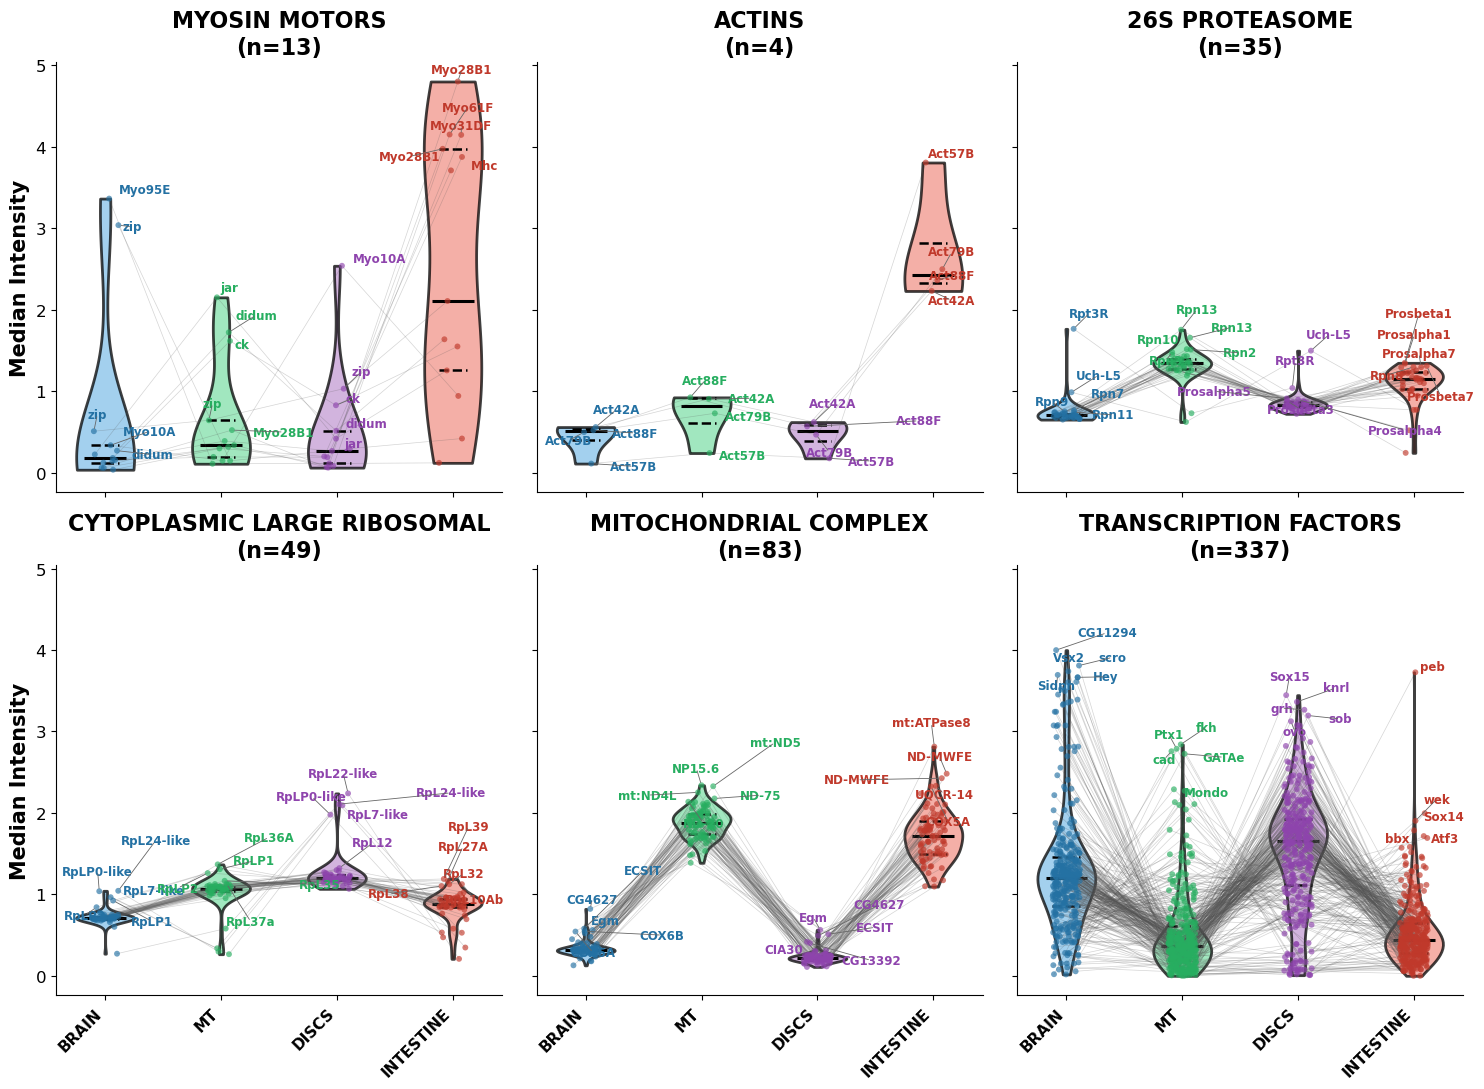

In [8]:
SEARCH_TERMS = ['MYOSIN MOTORS', 'ACTINS', '26S PROTEASOME',
                'CYTOPLASMIC LARGE RIBOSOMAL', 'MITOCHONDRIAL COMPLEX', 'TRANSCRIPTION FACTORS']
TOP_N = 5

gg = cm.read_gene_groups()
FBGN_COL = cm.detect_fbgn_col(result)
positions = list(range(len(tissues)))

fig, axes = plt.subplots(2, 3, figsize=(15.0, 11.0), sharex=True, sharey=True, squeeze=False)
for ax, term in zip(axes.flatten(), SEARCH_TERMS):
    fbgns = set(gg.loc[gg['FB_group_name'].str.contains(term, case=False, na=False, regex=False),
                       'Group_member_FB_gene_id'].dropna())
    matched = result[result[FBGN_COL].isin(fbgns)]
    med = {t: matched[cond_to_cols[t]].median(axis=1).values for t in tissues}
    valid = np.logical_and.reduce([np.isfinite(med[t]) for t in tissues])
    plot_data = [med[t][valid] for t in tissues]
    n_pts = int(valid.sum())
    gene_names = matched.loc[valid, 'gene_symbol'].astype(str).values

    parts = ax.violinplot(plot_data, positions=positions, showmeans=False, showmedians=False, showextrema=False)
    for pc, t in zip(parts['bodies'], tissues):
        pc.set_facecolor(TISSUE_COLORS_LIGHT[t]); pc.set_edgecolor('black'); pc.set_linewidth(2.0); pc.set_alpha(0.75)
    for pos, v in zip(positions, plot_data):
        q25, q50, q75 = np.percentile(v, [25, 50, 75])
        ax.hlines(q50, pos - 0.18, pos + 0.18, color='black', linewidth=2.2)
        ax.hlines([q25, q75], pos - 0.12, pos + 0.12, color='black', linewidth=1.8, linestyle='--')

    rng = np.random.default_rng(42)
    jitters = {t: rng.uniform(-0.12, 0.12, size=n_pts) for t in tissues}
    for j in range(n_pts):
        ax.plot([positions[k] + jitters[tissues[k]][j] for k in range(len(tissues))],
                [plot_data[k][j] for k in range(len(tissues))], color='#555555', linewidth=0.5, alpha=0.25, zorder=2)
    for k, t in enumerate(tissues):
        ax.scatter(positions[k] + jitters[t], plot_data[k], s=18, color=TISSUE_COLORS_DARK[t],
                   alpha=0.65, edgecolors='none', zorder=3)

    texts = []
    for k, t in enumerate(tissues):
        for j in np.argsort(plot_data[k])[::-1][:min(TOP_N, n_pts)]:
            texts.append(ax.text(positions[k] + jitters[t][j], plot_data[k][j], gene_names[j],
                                 fontsize=8.5, fontweight='bold', color=TISSUE_COLORS_DARK[t]))
    adjust_text(texts, ax=ax, expand_points=(1.4, 1.6), expand_text=(1.3, 1.5),
                force_text=(0.4, 0.6), only_move={'text': 'xy'},
                arrowprops=dict(arrowstyle='-', color='0.4', lw=0.6))

    ax.set_title(f'{term}\n(n={n_pts})', fontsize=16, fontweight='bold')
    ax.set_xticks(positions)
    ax.set_xticklabels([TISSUE_LABELS[t] for t in tissues], fontsize=11, fontweight='bold', rotation=45, ha='right')
    ax.tick_params(axis='y', labelsize=12)
    ax.spines[['top', 'right']].set_visible(False)
    print(f'{term}: {n_pts} proteins')

for r in range(2):
    axes[r, 0].set_ylabel('Median Intensity', fontsize=15, fontweight='bold')
fig.tight_layout()
cm.save_fig(fig, OUT, 'fig5C_gene_group_violins')
plt.show()

## Fig 5D — tissue-prevalent and tissue-enriched proteins
Significantly higher in T than in every other tissue (padj < 0.05); tier from the smallest log2FC (vs the closest tissue):
light = 1 ≤ min log2FC < 3.33 (2–10×), dark = min log2FC ≥ 3.33 (> 10×).

BRAIN  prevalent 2-10x:  347   enriched >10x:  363
GUT    prevalent 2-10x:  308   enriched >10x:  230
MT     prevalent 2-10x:  537   enriched >10x:  173
DISCS  prevalent 2-10x:  432   enriched >10x:   32


Saved fig5/fig5D_enriched_stacked_bars.pdf / .png


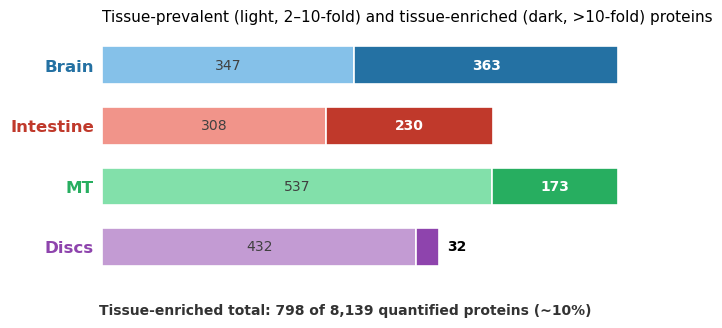

In [9]:
LOW_LOG2, EXCL_LOG2 = 1.0, 3.33
order = ['brain', 'gut', 'mt', 'discs']          # top -> bottom

counts = {}
for t in order:
    others = [o for o in tissues if o != t]
    l2 = pd.DataFrame({o: np.log2(results[f'fc_{t}_vs_{o}'].clip(lower=1e-10)) for o in others})
    sig_up = pd.DataFrame({o: (results[f'padj_{t}_vs_{o}'] < PVALUE_THRESHOLD) & (l2[o] > 0) for o in others}).all(axis=1)
    margin = l2.min(axis=1)
    counts[t] = (int((sig_up & (margin >= LOW_LOG2) & (margin < EXCL_LOG2)).sum()),
                 int((sig_up & (margin >= EXCL_LOG2)).sum()))
    print(f'{t.upper():6s} prevalent 2-10x: {counts[t][0]:4d}   enriched >10x: {counts[t][1]:4d}')

n_total, n_excl = len(results), sum(c[1] for c in counts.values())
xmax = max(sum(c) for c in counts.values())
min_inside = 0.07 * xmax
fig, ax = plt.subplots(figsize=(7.0, 0.55 * len(order) + 1.1))
for yi, t in enumerate(order):
    n_enr, n_exc = counts[t]
    ax.barh(yi, n_enr, height=0.62, color=TISSUE_COLORS_LIGHT[t], edgecolor='white', linewidth=1.2)
    ax.barh(yi, n_exc, left=n_enr, height=0.62, color=TISSUE_COLORS_DARK[t], edgecolor='white', linewidth=1.2)
    if n_enr >= min_inside:
        ax.text(n_enr / 2, yi, f'{n_enr}', ha='center', va='center', fontsize=10, color='0.25')
    elif n_enr > 0:
        ax.text(n_enr + n_exc + xmax * 0.015, yi, f'{n_enr}', ha='left', va='center', fontsize=10, color='0.25')
    if n_exc >= min_inside:
        ax.text(n_enr + n_exc / 2, yi, f'{n_exc}', ha='center', va='center', fontsize=10, fontweight='bold', color='white')
    elif n_exc > 0:
        ax.text(n_enr + n_exc + xmax * 0.015, yi, f'{n_exc}', ha='left', va='center', fontsize=10,
                fontweight='bold', color='black')
ax.set_yticks(range(len(order)))
ax.set_yticklabels([{'mt': 'MT', 'gut': 'Intestine'}.get(t, t.capitalize()) for t in order],
                   fontsize=12, fontweight='bold')
for lbl, t in zip(ax.get_yticklabels(), order):
    lbl.set_color(TISSUE_COLORS_DARK[t])
ax.invert_yaxis()
ax.tick_params(axis='y', length=0, pad=6)
ax.set_xlim(0, xmax * 1.12)
ax.set_xticks([])
for s in ax.spines.values():
    s.set_visible(False)
ax.set_title('Tissue-prevalent (light, 2–10-fold) and tissue-enriched (dark, >10-fold) proteins',
             fontsize=11, loc='left', pad=10)
fig.text(0.5, 0.02, f'Tissue-enriched total: {n_excl:,} of {n_total:,} quantified proteins (~{100 * n_excl / n_total:.0f}%)',
         ha='center', va='bottom', fontsize=10, fontweight='bold', color='0.2')
fig.tight_layout(rect=[0, 0.10, 1, 1])
cm.save_fig(fig, OUT, 'fig5D_enriched_stacked_bars')
plt.show()

## Fig 5E — GO enrichment of tissue-enriched proteins
g:Profiler per tissue (*D. melanogaster*, GO:BP + GO:MF, g:SCS, p < 0.05), background = all quantified genes; top 3
terms per tissue.

BRAIN: 347 genes, 100 significant terms


MT: 168 genes, 18 significant terms


DISCS: 32 genes, 0 significant terms


GUT: 221 genes, 16 significant terms


Saved fig5/fig5E_go_dotplot.pdf / .png


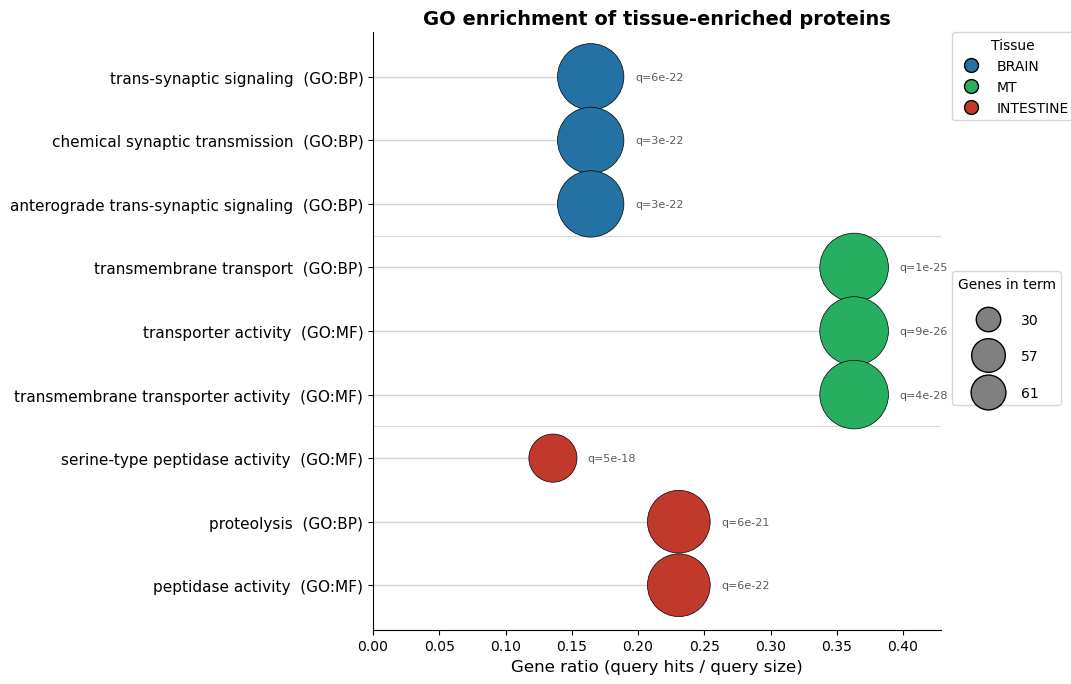

In [10]:
from gprofiler import GProfiler

gp = GProfiler(return_dataframe=True)
background = results.loc[results[FBGN_COL].notna(), FBGN_COL].unique().tolist()
go_parts = []
for t in tissues:
    genes = results.loc[(results['exclusive_to'] == t) & results[FBGN_COL].notna(), FBGN_COL].unique().tolist()
    res = gp.profile(organism='dmelanogaster', query=genes, background=background, sources=['GO:BP', 'GO:MF'],
                     significance_threshold_method='g_SCS', user_threshold=0.05, no_evidences=True)
    print(f'{t.upper()}: {len(genes)} genes, {len(res)} significant terms')
    if not res.empty:
        go_parts.append(res.sort_values('p_value').head(3).assign(tissue=t))
go_all = pd.concat(go_parts, ignore_index=True)
go_all['neg_log10_pval'] = -np.log10(go_all['p_value'].clip(lower=1e-300))

tissue_order = [t for t in tissues if (go_all['tissue'] == t).any()]
df = (go_all.assign(_torder=go_all['tissue'].map({t: i for i, t in enumerate(tissue_order)}))
            .sort_values(['_torder', 'neg_log10_pval']).reset_index(drop=True))
labels = [f"{r['name']}  ({r['source']})" for _, r in df.iterrows()]
y = np.arange(len(df))
x = df['precision'].to_numpy(float)
sizes = df['intersection_size'].to_numpy(float) * 40.0

fig, ax = plt.subplots(figsize=(11, 0.55 * len(df) + 2))
for xi, yi in zip(x, y):
    ax.plot([0, xi], [yi, yi], color='lightgray', lw=1, zorder=1)
ax.scatter(x, y, s=sizes, c=[TISSUE_COLORS_DARK[t] for t in df['tissue']], edgecolor='black', linewidth=0.5, zorder=3)
ax.set_yticks(y)
ax.set_yticklabels(labels, fontsize=11)
ax.set_xlabel('Gene ratio (query hits / query size)', fontsize=12)
ax.set_xlim(0, float(x.max()) * 1.18)
ax.set_ylim(-0.7, len(df) - 0.3)
for b in np.where(df['tissue'].values[:-1] != df['tissue'].values[1:])[0] + 0.5:
    ax.axhline(b, color='0.85', lw=0.8, zorder=0)
for xi, yi, s, nlp in zip(x, y, sizes, df['neg_log10_pval']):
    ax.annotate(f'q={10 ** -nlp:.0e}', xy=(xi, yi), xytext=(np.sqrt(s / np.pi) + 5, 0), textcoords='offset points',
                va='center', ha='left', fontsize=8, color='0.35', annotation_clip=False)
ax.spines[['top', 'right']].set_visible(False)
ax.set_title('GO enrichment of tissue-enriched proteins', fontsize=14, fontweight='bold')
ax.invert_yaxis()

tissue_handles = [Line2D([], [], marker='o', linestyle='', markersize=10, markerfacecolor=TISSUE_COLORS_DARK[t],
                         markeredgecolor='black', label=TISSUE_LABELS[t]) for t in tissue_order]
leg = ax.legend(handles=tissue_handles, title='Tissue', loc='upper left', bbox_to_anchor=(1.02, 1.0),
                frameon=True, borderaxespad=0)
ax.add_artist(leg)
size_vals = sorted(df['intersection_size'].unique())
pick = list(dict.fromkeys([size_vals[0], size_vals[len(size_vals) // 2], size_vals[-1]]))
size_handles = [Line2D([], [], marker='o', linestyle='', markeredgecolor='black', markerfacecolor='gray',
                       markersize=2 * np.sqrt(n * 40.0 / np.pi) * 0.45, label=str(n)) for n in pick]
ax.legend(handles=size_handles, title='Genes in term', loc='upper left', bbox_to_anchor=(1.02, 0.60),
          frameon=True, borderaxespad=0, labelspacing=1.6, handletextpad=1.4)
plt.tight_layout()
cm.save_fig(fig, OUT, 'fig5E_go_dotplot')
plt.show()